# 01 · EDA

PhiUSIIL: 235,795 URLs. Looking at class balance, length, TLDs, subdomains and HTTPS, and checking for shortcuts before any model sees the data.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from phishing.data import download, load

download()
df = load()
df.shape

(235795, 3)

Careful: in the raw file `label = 1` means **legitimate**. `load()` flips it to `is_phishing` so 1 = phishing everywhere in this project.

In [2]:
df["is_phishing"].value_counts(normalize=True).round(3)

is_phishing
0    0.572
1    0.428
Name: proportion, dtype: float64

57% legitimate, 43% phishing. Balanced enough that accuracy isn't useless, but the metric will still be recall at a fixed false-positive rate.

## The shortcut

First thing I noticed scrolling through: every legitimate URL looks the same.

In [3]:
df.groupby("is_phishing")["url"].apply(lambda s: s.sample(5, random_state=0).tolist())

is_phishing
0    [https://www.xmasdirect.co.uk, https://www.all...
1    [http://www.saiconsard.co.jp.mfouei.top/ai/sig...
Name: url, dtype: object

In [4]:
bare_www_https = df["url"].str.match(r"^https://www\.[^/?#]+/?$")
pd.crosstab(bare_www_https, df["is_phishing"], normalize="columns").round(4)

is_phishing,0,1
url,,
False,0.0,0.9897
True,1.0,0.0103


In [5]:
rule = (~bare_www_https).astype(int)  # 'not a bare https://www homepage' -> phishing
print("accuracy", round((rule == df["is_phishing"]).mean(), 4))
print("phishing recall", round(rule[df["is_phishing"] == 1].mean(), 4))
print("false-positive rate", round(rule[df["is_phishing"] == 0].mean(), 4))

accuracy 0.9956
phishing recall 0.9897
false-positive rate 0.0


A one-line rule with no ML gets 99.56% accuracy and zero false positives. **100% of legitimate URLs are `https://www.<domain>` with no path.** The legit side was collected as homepages, the phishing side as full links.

A model trained on raw URLs would mostly learn this formatting difference, and it would flag every real legit link with a path (`https://github.com/user/repo`) as phishing.

Decision: the main model uses the **hostname only** (no scheme, no `www.`, no path). Path features need legit URLs with paths from another source. Parked for Day 6.

Dead end: I first planned to just drop `IsHTTPS` and keep the rest of the URL. That doesn't fix it, because `www.` and "has a path" give the same shortcut.

## Hostname-level look

In [6]:
h = df["hostname"]
feat = pd.DataFrame(
    {
        "length": h.str.len(),
        "dots": h.str.count(r"\."),
        "hyphens": h.str.count("-"),
        "digits": h.str.count(r"\d"),
        "punycode": h.str.contains("xn--"),
        "is_phishing": df["is_phishing"],
    }
)
feat.groupby("is_phishing").median(numeric_only=True)

,length,dots,hyphens,digits,punycode
is_phishing,,,,,
0,15.0,1.0,0.0,0.0,0.0
1,20.0,2.0,0.0,0.0,0.0


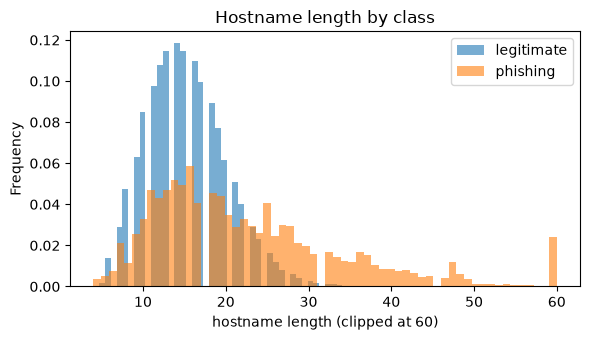

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for label, name in [(0, "legitimate"), (1, "phishing")]:
    feat.loc[feat.is_phishing == label, "length"].clip(upper=60).plot.hist(
        bins=60, alpha=0.6, density=True, ax=ax, label=name
    )
ax.set(xlabel="hostname length (clipped at 60)", title="Hostname length by class")
ax.legend()
fig.tight_layout()
fig.savefig("../reports/figures/hostname_length.png", dpi=120)

In [8]:
feat.groupby("is_phishing")[["hyphens", "digits"]].apply(lambda g: (g > 0).mean()).round(3)

,hyphens,digits
is_phishing,,
0,0.075,0.026
1,0.312,0.360


In [9]:
feat.groupby("is_phishing")["punycode"].sum()

is_phishing
0      0
1    154
Name: punycode, dtype: int64

## TLDs

In [10]:
tld = h.str.rsplit(".", n=1).str[-1]
rate = df.groupby(tld)["is_phishing"].agg(["mean", "size"])
rate[rate["size"] >= 500].sort_values("mean", ascending=False).head(12).round(3)

,mean,size
hostname,,
cf,1.000,1203
top,0.999,2329
ml,0.999,995
site,0.997,1482
ga,0.996,1111
link,0.995,1463
dev,0.986,2345
xyz,0.983,1473
app,0.978,6508


`.app`, `.io`, `.dev` and similar lean heavily phishing. A lot of that is free hosting (`*.web.app`, `*.firebaseapp.com`, `*.github.io`), so the *registered domain* matters, not just the TLD.

In [11]:
free_hosts = [
    "web.app",
    "firebaseapp.com",
    "github.io",
    "vercel.app",
    "netlify.app",
    "pages.dev",
    "godaddysites.com",
    "weebly.com",
    "wixsite.com",
]
on_free = h.apply(lambda x: any(x.endswith("." + f) for f in free_hosts))
pd.crosstab(on_free, df["is_phishing"])

is_phishing,0,1
hostname,,
False,134850,86919
True,0,14026


Second bias: **zero** legitimate URLs are on free hosting, against 14,026 phishing ones. In real life plenty of legit sites live on `github.io` or `vercel.app`, so a "free host" feature would look perfect here and over-flag in practice. Keep it, but test it on real legit free-hosted sites before trusting it.

## Duplicates and overlap

In [12]:
print("duplicate URLs", df["url"].duplicated().sum())
both = df.groupby("hostname")["is_phishing"].nunique()
print("hostnames with both labels", (both > 1).sum())

duplicate URLs 425


hostnames with both labels 58


## Notes for the feature extractor (Day 3)

- Hostname only for now: length, dots/subdomain count, hyphens, digits, punycode, TLD, entropy, known free-hosting suffix.
- Split by registered domain so the same site can't sit in train and test.
- The 99.56% rule is the number any model has to be honest about. Report results on hostnames, never on raw URLs.